In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
data=pd.read_csv(r'Telecom_Customer_Churn.csv')

In [5]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
data.shape

(7043, 21)

In [8]:
data.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [9]:
!pip install sweetviz

   ---------------------------------------- 0.0/15.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/15.1 MB ? eta -:--:--
    --------------------------------------- 0.3/15.1 MB ? eta -:--:--
    --------------------------------------- 0.3/15.1 MB ? eta -:--:--
   - -------------------------------------- 0.5/15.1 MB 730.2 kB/s eta 0:00:20
   -- ------------------------------------- 0.8/15.1 MB 797.1 kB/s eta 0:00:18
   -- ------------------------------------- 1.0/15.1 MB 861.9 kB/s eta 0:00:17
   --- ------------------------------------ 1.3/15.1 MB 1.0 MB/s eta 0:00:14
   ---- ----------------------------------- 1.6/15.1 MB 1.1 MB/s eta 0:00:13
   ----- ---------------------------------- 2.1/15.1 MB 1.2 MB/s eta 0:00:11
   ------ --------------------------------- 2.4/15.1 MB 1.3 MB/s eta 0:00:11
   ------ --------------------------------- 2.6/15.1 MB 1.3 MB/s eta 0:00:10
   --------- ------------------------------ 3.4/15.1 MB 1.5 MB/s eta 0:00:09
   ---------- -------

In [10]:
##to perform eda easily but only works when data is consistent and not have many missing value

import sweetviz as sv

report=sv.analyze(data)
report.show_html("report.html")

                                             |          | [  0%]   00:00 -> (? left)

findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight nor

Report report.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


In [11]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [12]:
## data transformation total charges is str make it float
# features are high we should identify relevent feature
# like customer_id doesnot affect churning so make it index

data.set_index('customerID' , inplace=True)
data['TotalCharges']=pd.to_numeric(data['TotalCharges'],errors='coerce').fillna(0).astype(int)

In [13]:
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
customerID,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29,No
5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889,No
3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108,Yes
7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840,No
9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151,Yes


#Label encoding

In [19]:
# caategoruial to numerical data

from sklearn.preprocessing import LabelEncoder

encode=data[['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService' , 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport','StreamingTV', 'StreamingMovies', 'Contract' , 'PaperlessBilling' , 'PaymentMethod', 'Churn']]
le=LabelEncoder()

for col in encode.columns:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])

In [20]:
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
customerID,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29,0
5575-GNVDE,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889,0
3668-QPYBK,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108,1
7795-CFOCW,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840,0
9237-HQITU,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151,1


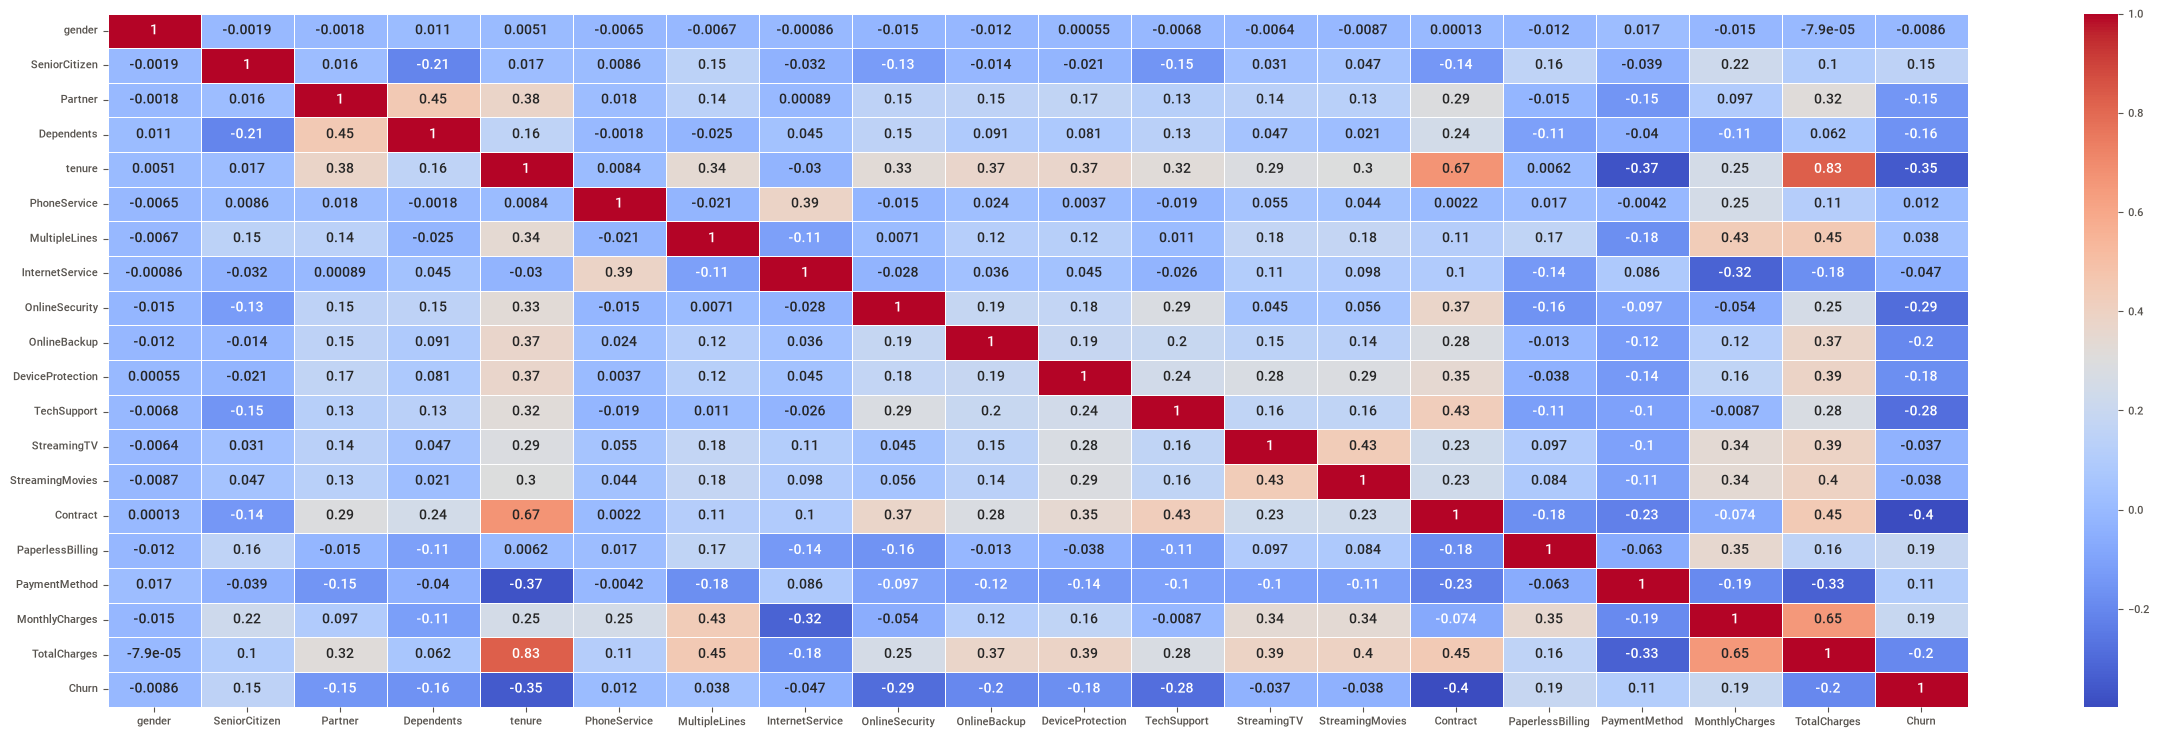

In [21]:
##correlation plot to select best features
plt.figure(figsize=(30,9))
sns.heatmap(data.corr(), annot=True, linewidths=0.5, cmap='coolwarm')
plt.show()

In [23]:
#selecting with positive correlation model (check once on gpt)

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.metrics import confusion_matrix

In [24]:
# X contains the selected features (independent variables) for the model
# y is the target variable (dependent variable) that we want to predict
X = data[['PhoneService', 'MultipleLines', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges']]  ## selecting only these features
y = data['Churn']

# Splitting the dataset into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the classifier
# Initializing the Decision Tree Classifier with the criterion as "entropy"
dt = DecisionTreeClassifier(criterion="entropy", random_state=42  ## THERE ARE GINI AND ENTROPY AS PARAMETER

# Training the Decision Tree classifier on the training data
dt.fit(x_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

In [25]:
## DT evaluation
# Predictions
# Making predictions on both training and testing datasets
train_preds = dt.predict(x_train)  # Predictions on the training set
test_preds = dt.predict(x_test)    # Predictions on the testing set

# Accuracy
# Calculating accuracy for both training and testing datasets
train_accuracy = accuracy_score(y_train, train_preds)  # Accuracy on the training set
test_accuracy = accuracy_score(y_test, test_preds)     # Accuracy on the testing set

# Printing the training and testing accuracies
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy: {test_accuracy:.4f}")

Training Accuracy: 0.9359
Testing Accuracy: 0.7012


findfont: Failed to find font weight normal, now using 500.


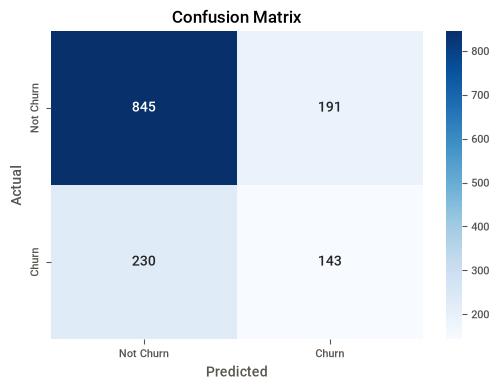

In [26]:
#CONFUSION MATRIX
# Generating the confusion matrix to evaluate the model's performance
cm = confusion_matrix(y_test, test_preds)

# Creating a heatmap to visualize the confusion matrix
plt.figure(figsize=(6, 4))  # Setting the figure size
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=["Not Churn", "Churn"], 
            yticklabels=["Not Churn", "Churn"])  # Adding labels for better interpretation
plt.xlabel("Predicted")  
plt.ylabel("Actual")     
plt.title("Confusion Matrix")  
plt.show()  # Display the plot

In [27]:
  # Classification Report
  # Printing the classification report for the testing data
  # The report includes metrics like precision, recall, F1-score, and support for each class
  print("Classification Report (Testing Data):\n")
  print(classification_report(y_test, test_preds))

Classification Report (Testing Data):

              precision    recall  f1-score   support

           0       0.79      0.82      0.80      1036
           1       0.43      0.38      0.40       373

    accuracy                           0.70      1409
   macro avg       0.61      0.60      0.60      1409
weighted avg       0.69      0.70      0.70      1409



findfont: Failed to find font weight normal, now using 500.


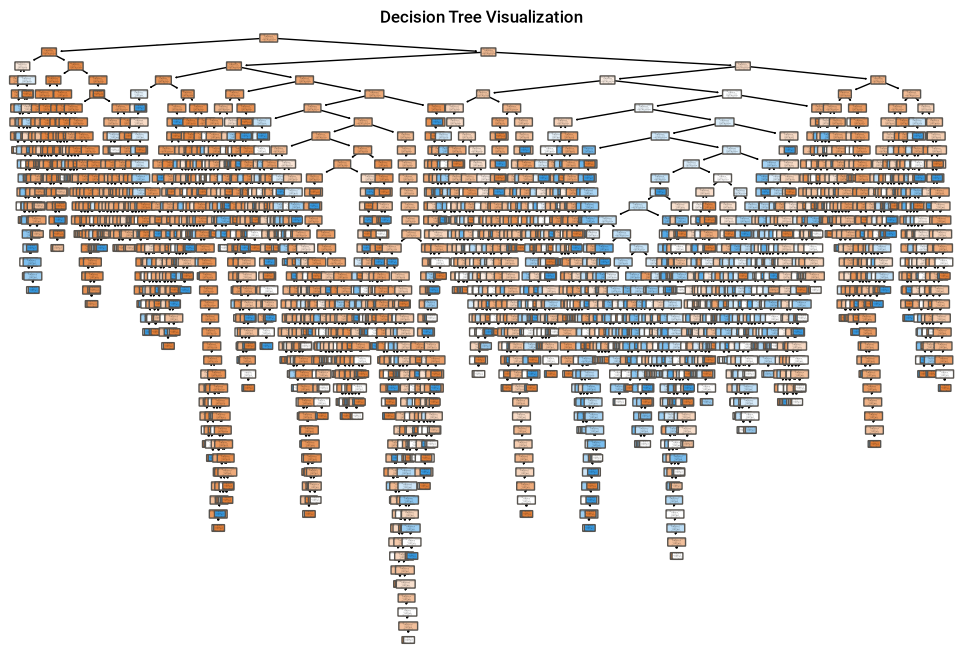

In [28]:
from sklearn.tree import plot_tree  # Importing the plot_tree function for visualizing the decision tree

# Set the size of the visualization plot for better readability
plt.figure(figsize=(12, 8))

# Plot the Decision Tree
plot_tree(
    dt,                            # The trained Decision Tree model
    filled=True,                   # Fill the nodes with colors to indicate class distribution
    feature_names=x_train.columns, # Use feature names for better interpretability
    class_names=["Class 0", "Class 1"], # Provide class names (e.g., "Class 0" and "Class 1")
    rounded=True                   # Round the corners of the nodes for a cleaner visual style
)

# Add a title to the plot for context
plt.title("Decision Tree Visualization")

# Display the generated tree visualization
plt.show()

findfont: Failed to find font weight normal, now using 500.


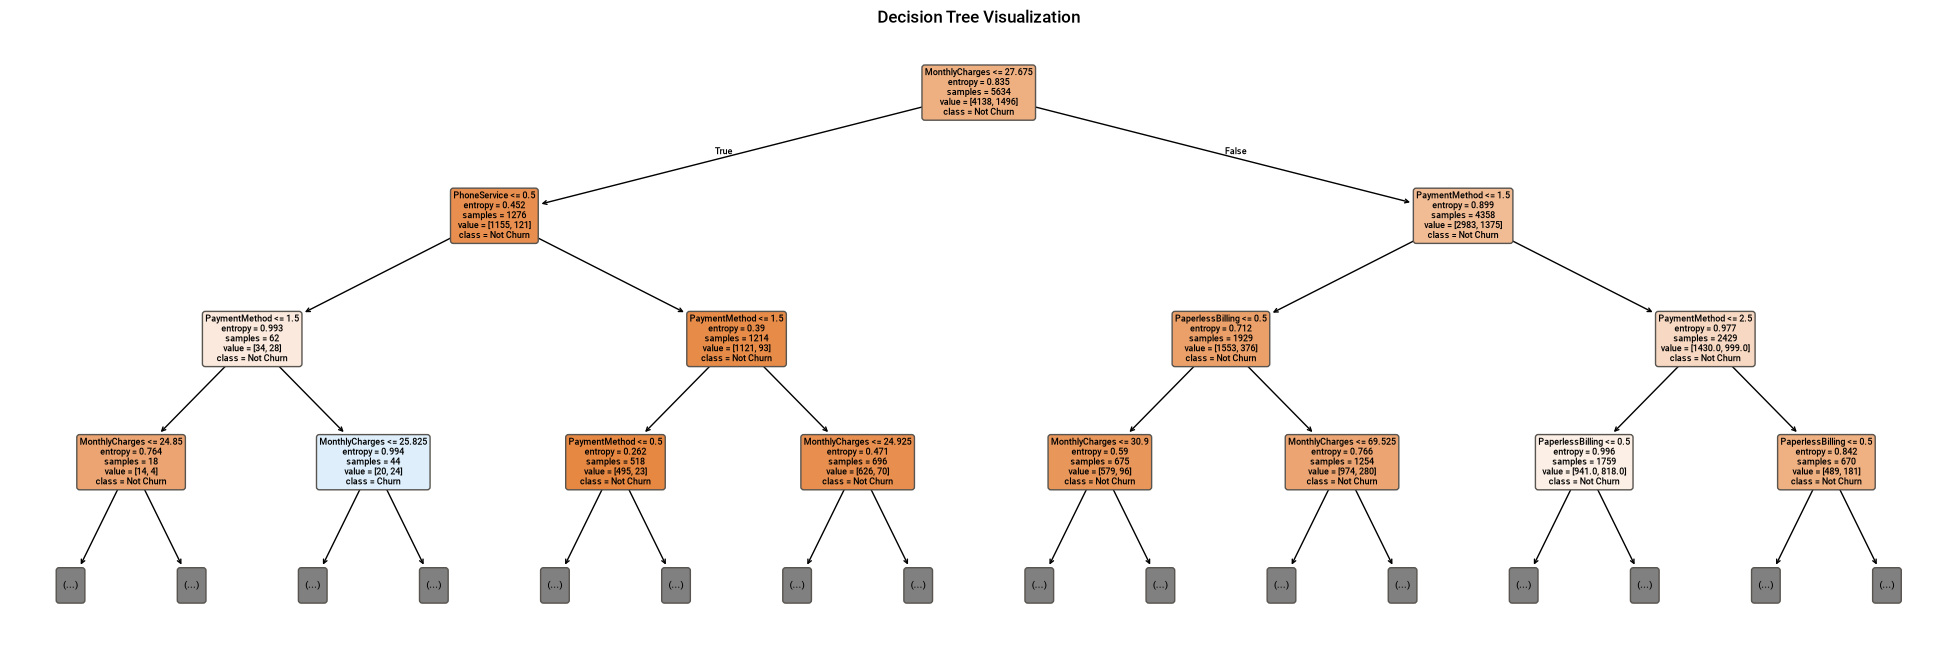

In [29]:
# Importing the function to visualize the Decision Tree
# from sklearn.tree import plot_tree

# Set the size of the plot for better visibility
plt.figure(figsize=(25, 8))

# Plot the Decision Tree
plot_tree(
    dt,                            # The Decision Tree model trained earlier
    filled=True,                   # Fill the nodes with colors to represent class distribution
    feature_names=x_train.columns, # Provide feature names for interpretability
    max_depth=3,                   # Limit the depth of the tree for visualization (optional)
    class_names=["Not Churn", "Churn"], # Provide class labels for better understanding
    rounded=True                   # Round the corners of the nodes for aesthetic improvement
)

# Set the title of the plot
plt.title("Decision Tree Visualization")

# Display the plot
plt.show()

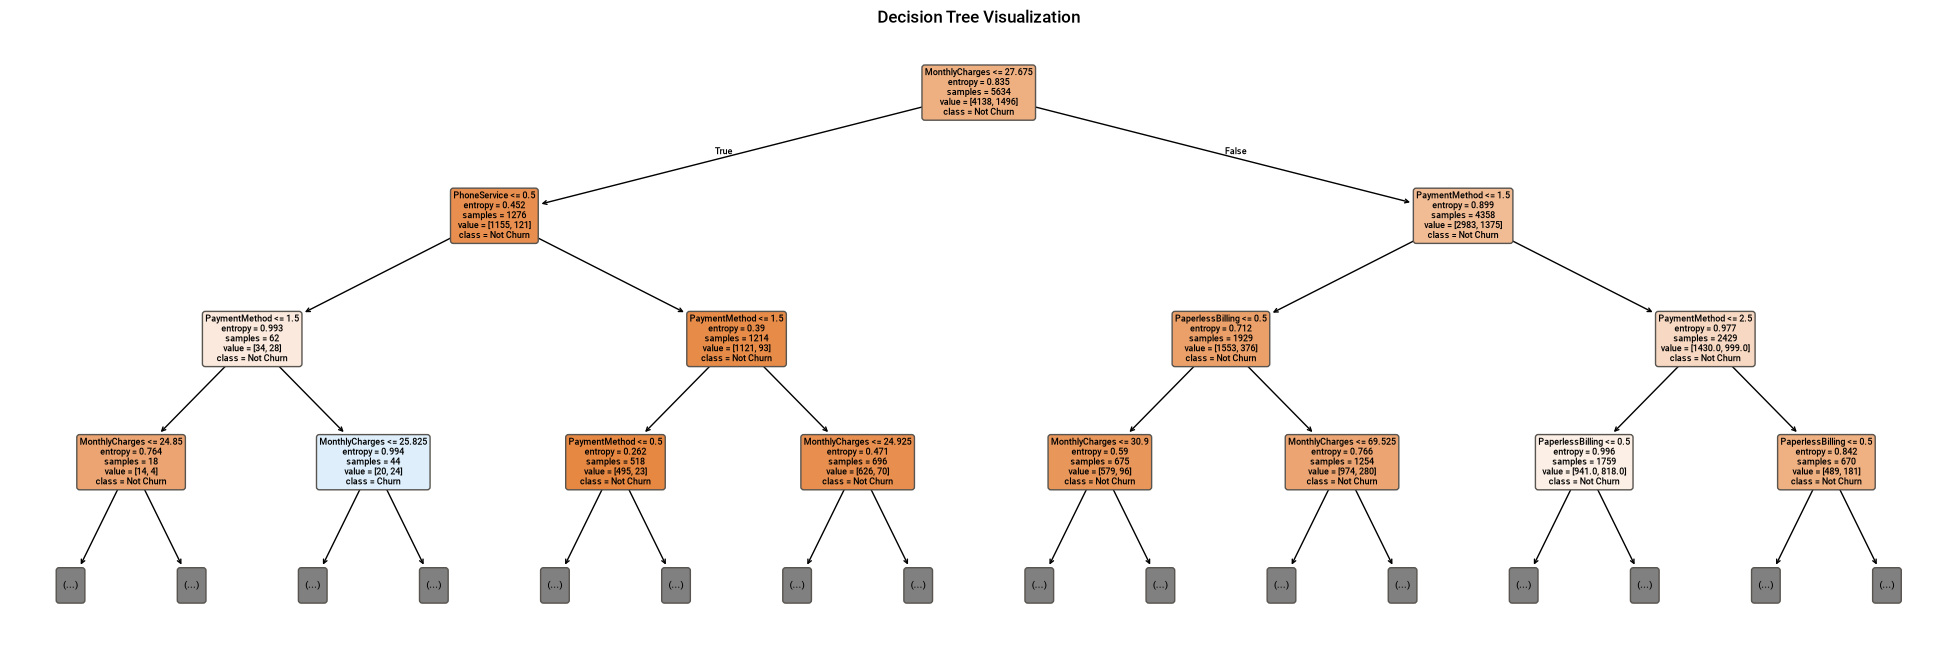

In [32]:
from sklearn.model_selection import cross_val_score

In [36]:
# k-fold cross-validation
cv_scores = cross_val_score(dt, X, y, cv=10, scoring='accuracy')

print(f"Accuracy for each fold: {cv_scores}")
# Calculate the mean and standard deviation of the accuracy scores
print(f"Mean Accuracy: {np.mean(cv_scores):.4f}")
print(f"Standard Deviation of Accuracy: {np.std(cv_scores):.4f}")

Accuracy for each fold: [0.6964539  0.69219858 0.69787234 0.70738636 0.69886364 0.70454545
 0.67471591 0.68607955 0.67613636 0.67045455]
Mean Accuracy: 0.6905
Standard Deviation of Accuracy: 0.0123


In [44]:
from sklearn.model_selection import StratifiedKFold

# Initialize StratifiedKFold with k splits
skf = StratifiedKFold(n_splits=5, shuffle=True,random_state=42)

# Perform cross-validation with StratifiedKFold
cv_scores = cross_val_score(dt, X, y, cv=skf, scoring='accuracy')

print(f"Accuracy for each fold: {cv_scores}")

# Calculate the mean and standard deviation of the accuracy scores
print(f"Mean Accuracy: {np.mean(cv_scores):.4f}")
print(f"Standard Deviation of Accuracy: {np.std(cv_scores):.4f}")

Accuracy for each fold: [0.70120653 0.68062456 0.68559262 0.67045455 0.69176136]
Mean Accuracy: 0.6859
Standard Deviation of Accuracy: 0.0103


In [45]:
# Cross-validation for precision, recall, and f1-score
precision_scores = cross_val_score(dt, X, y, cv=5, scoring='precision')
recall_scores = cross_val_score(dt, X, y, cv=5, scoring='recall')
f1_scores = cross_val_score(dt, X, y, cv=5, scoring='f1')

# Print the results
print(f"Precision for each fold: {precision_scores}")
print(f"Recall for each fold: {recall_scores}")
print(f"F1-score for each fold: {f1_scores}")

# Calculate and print the mean and standard deviation of each metric
print(f"Mean Precision: {np.mean(precision_scores):.4f}, Std: {np.std(precision_scores):.4f}")
print(f"Mean Recall: {np.mean(recall_scores):.4f}, Std: {np.std(recall_scores):.4f}")
print(f"Mean F1-score: {np.mean(f1_scores):.4f}, Std: {np.std(f1_scores):.4f}")

Precision for each fold: [0.39308176 0.40184049 0.41945289 0.38125    0.3988604 ]
Recall for each fold: [0.3342246  0.35026738 0.36898396 0.32707775 0.37433155]
F1-score for each fold: [0.36127168 0.37428571 0.39260313 0.35209235 0.3862069 ]
Mean Precision: 0.3989, Std: 0.0125
Mean Recall: 0.3510, Std: 0.0186
Mean F1-score: 0.3733, Std: 0.0151


C:\Users\HP\AppData\Local\Temp\ipykernel_1780\3527704502.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot([cv_scores], vert=False)
C:\Users\HP\AppData\Local\Temp\ipykernel_1780\3527704502.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot([precision_scores], vert=False)
C:\Users\HP\AppData\Local\Temp\ipykernel_1780\3527704502.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot([f1_scores], vert=False)


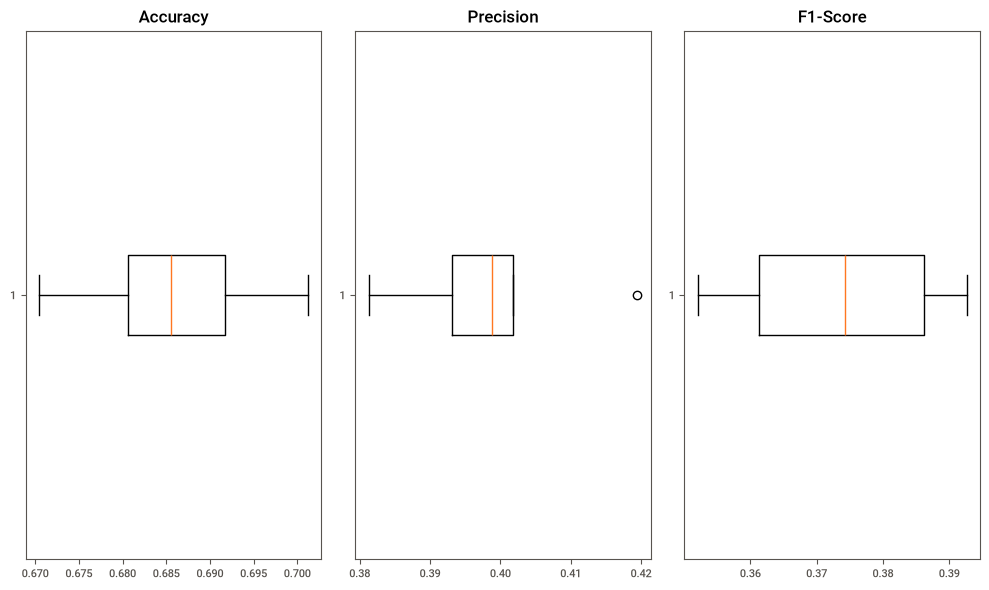

In [46]:
# Plotting the cross-validation scores for each fold
plt.figure(figsize=(10, 6))

# Accuracy plot
plt.subplot(1, 3, 1)
plt.boxplot([cv_scores], vert=False)
plt.title('Accuracy')

# Precision plot
plt.subplot(1, 3, 2)
plt.boxplot([precision_scores], vert=False)
plt.title('Precision')

# F1-Score plot
plt.subplot(1, 3, 3)
plt.boxplot([f1_scores], vert=False)
plt.title('F1-Score')

plt.tight_layout()
plt.show()